In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import xarray as xr
import pysal
import sklearn
import xgboost
import shap



In [2]:
print("🎉 Success! Your PhD Python environment is completely ready.")

🎉 Success! Your PhD Python environment is completely ready.


In [3]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
print("All analysis packages loaded successfully!")

Matplotlib is building the font cache; this may take a moment.


All analysis packages loaded successfully!


In [1]:
!pip install copernicusmarine[extra]

zsh:1: no matches found: copernicusmarine[extra]


In [2]:
!pip install "copernicusmarine[extra]"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 7.5 MB/s  0:00:0013.1 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 23.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.2/16.2 MB 25.0 MB/s  0:00:00a 0:00:010:00:0101
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 8.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.8/39.8 MB 20.2 MB/s  0:00:01 eta 0:00:010:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 20.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 24.2 MB/s  0:00:00
  Attempting uninstall: python-dateutil━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  3/51 [semver]
    Found existing installation: python-dateutil 4.0.0━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  3/51 [semver]
    Uninstalling python-dateutil-4.0.0:━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  3/51 [semver]
      Successfully uninstalled python-dateutil-4.0.0━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  3/51 [semver]
  Attempting uninstall: netcdf4━

In [3]:
import os
import numpy as np
import xarray as xr
import copernicusmarine

print("Ready to fetch Copernicus data.")


Ready to fetch Copernicus data.


/Users/macbookpro2020/miniconda3/envs/nigerdelta/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
!pip install ipywidgets jupyterlab_widgets


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 22.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ipywidgets]━━━━━━━ 2/3 [ipywidgets]


In [5]:
# 1. Configuration for the Niger Delta bounding box subset
OUTPUT_DIRECTORY = "./data"
OUTPUT_FILENAME = "niger_delta_currents.nc"

# Define the Copernicus Global Ocean Physics Forecast product ID
# This product contains 'uo' (eastward) and 'vo' (northward) water velocity data
DATASET_ID = "cmems_mod_glo_phy_anfc_0.083deg_PT1H-m" 

print("Downloading dataset subset from Copernicus Marine Service...")

# 2. Execute the subset download command programmatically
# When you run this cell, it will securely prompt you for your Copernicus Username and Password
try:
    copernicusmarine.get(
        dataset_id=DATASET_ID,
        variables=["uo", "vo"],
        minimum_longitude=3.0,
        maximum_longitude=9.0,
        minimum_latitude=3.0,
        maximum_latitude=6.0,
        output_directory=OUTPUT_DIRECTORY,
        output_filename=OUTPUT_FILENAME,
        force_download=True
    )
    print(f"🎉 Success! File downloaded to: {OUTPUT_DIRECTORY}/{OUTPUT_FILENAME}")
except Exception as e:
    print(f"Error during download configuration: {e}")
    print("Ensure your Copernicus Marine credentials are active and dataset ID matches current catalog updates.")


WARNING - 2026-11-09T14:51:10Z - 'force_download' has been deprecated.


Error during download configuration: get() got an unexpected keyword argument 'variables'
Ensure your Copernicus Marine credentials are active and dataset ID matches current catalog updates.


In [6]:
import os
import numpy as np
import xarray as xr
import copernicusmarine

# 1. Configuration for the Niger Delta bounding box subset
OUTPUT_DIRECTORY = "./data"
OUTPUT_FILENAME = "niger_delta_currents.nc"
DATASET_ID = "cmems_mod_glo_phy_anfc_0.083deg_PT1H-m" 

print("Downloading dataset subset from Copernicus Marine Service...")

# 2. Execute the updated subset download command
try:
    copernicusmarine.get(
        dataset_id=DATASET_ID,
        variable=["uo", "vo"],  # Changed from 'variables' to 'variable'
        minimum_longitude=3.0,
        maximum_longitude=9.0,
        minimum_latitude=3.0,
        maximum_latitude=6.0,
        output_directory=OUTPUT_DIRECTORY,
        output_filename=OUTPUT_FILENAME,
        # 'force_download' removed as it is deprecated
    )
    print(f"🎉 Success! File downloaded to: {OUTPUT_DIRECTORY}/{OUTPUT_FILENAME}")
except Exception as e:
    print(f"Error during download configuration: {e}")



Error during download configuration: get() got an unexpected keyword argument 'variable'


In [ ]:
import os
import copernicusmarine

# 1. Configuration for the Niger Delta bounding box subset
OUTPUT_DIRECTORY = "./data"
OUTPUT_FILENAME = "niger_delta_currents.nc"
DATASET_ID = "cmems_mod_glo_phy_anfc_0.083deg_PT1H-m" 

print("Downloading dataset subset from Copernicus Marine Service...")

# 2. Execute the official subset tool
try:
    copernicusmarine. subset(
        dataset_id=DATASET_ID,
        variables=["uo", "vo"],  # Plural is correct for the subset function
        minimum_longitude=3.0,
        maximum_longitude=9.0,
        minimum_latitude=3.0,
        maximum_latitude=6.0,
        output_directory=OUTPUT_DIRECTORY,
        output_filename=OUTPUT_FILENAME
    )
    print(f"🎉 Success! File downloaded to: {OUTPUT_DIRECTORY}/{OUTPUT_FILENAME}")
except Exception as e:
    print(f"Error during download configuration: {e}")
    


In [ ]:
import os
import copernicusmarine

OUTPUT_DIRECTORY = "./data"
OUTPUT_FILENAME = "niger_delta_currents.nc"
DATASET_ID = "cmems_mod_glo_phy_anfc_0.083deg_PT1H-m"

print("Starting explicit authentication and subset download...")

try:
    copernicusmarine.subset(
        dataset_id=DATASET_ID,
        variables=["uo", "vo"],
        minimum_longitude=3.0,
        maximum_longitude=9.0,
        minimum_latitude=3.0,
        maximum_latitude=6.0,
        output_directory=OUTPUT_DIRECTORY,
        output_filename=OUTPUT_FILENAME,
        # Provide credentials explicitly to skip interactive prompts:
        username="YOUR_COPERNICUS_USERNAME",  
        password="YOUR_COPERNICUS_PASSWORD"
    )
    print(f"🎉 Success! File downloaded to: {OUTPUT_DIRECTORY}/{OUTPUT_FILENAME}")
except Exception as e:
    print(f"Error during subset execution: {e}")


In [ ]:
import os
os.environ["COPERNICUSMARINE_USER"] = "Augie"
os.environ["COPERNICUSMARINE_PASSWORD"] = "Gunners888%%"
print("Credentials mapped into the system environment.")


In [1]:
import os
import logging
import copernicusmarine

# 1. Force the tool to print background progress logs directly into your cell
logging.basicConfig(level=logging.INFO)

OUTPUT_DIRECTORY = "./data"
OUTPUT_FILENAME = "niger_delta_currents.nc"
DATASET_ID = "cmems_mod_glo_phy_anfc_0.083deg_PT1H-m"

print("Requesting a highly targeted 1-day time slice to prevent server-side hanging...")

try:
    copernicusmarine.subset(
        dataset_id=DATASET_ID,
        variables=["uo", "vo"],
        minimum_longitude=3.0,
        maximum_longitude=9.0,
        minimum_latitude=3.0,
        maximum_latitude=6.0,
        
        # Explicitly restrict the download timeframe to just 24 hours
        start_datetime="2026-11-01T00:00:00",
        end_datetime="2026-11-02T00:00:00",
        
        output_directory=OUTPUT_DIRECTORY,
        output_filename=OUTPUT_FILENAME,
        
        # Explicit login to bypass interactive lockups
        username="YOUR_COPERNICUS_USERNAME",  
        password="YOUR_COPERNICUS_PASSWORD"
    )
    print(f"🎉 Success! File downloaded to: {OUTPUT_DIRECTORY}/{OUTPUT_FILENAME}")
except Exception as e:
    print(f"Process stopped with details: {e}")


Requesting a highly targeted 1-day time slice to prevent server-side hanging...
Process stopped with details: Learn how to recover your credentials at: https://help.marine.copernicus.eu/en/articles/4444552-i-forgot-my-username-or-my-password-what-should-i-do


In [2]:
import os
import logging
import copernicusmarine

# 1. Enable background tracking logs so you see real-time download status
logging.basicConfig(level=logging.INFO)

# 2. Enter your validated Copernicus details here
COPERNICUS_USERNAME = "Augie"
COPERNICUS_PASSWORD = "Gunners888%%"

# 3. Setup files and targets for your PhD area (Niger Delta)
OUTPUT_DIRECTORY = "./data"
OUTPUT_FILENAME = "niger_delta_currents.nc"
DATASET_ID = "cmems_mod_glo_phy_anfc_0.083deg_PT1H-m"

print("Initializing secure Copernicus download process...")

try:
    copernicusmarine.subset(
        dataset_id=DATASET_ID,
        variables=["uo", "vo"],
        minimum_longitude=3.0,
        maximum_longitude=9.0,
        minimum_latitude=3.0,
        maximum_latitude=6.0,
        
        # Pulling a light 1-day timeframe to keep calculations fast on your Intel Core i5
        start_datetime="2026-11-01T00:00:00",
        end_datetime="2026-11-02T00:00:00",
        
        output_directory=OUTPUT_DIRECTORY,
        output_filename=OUTPUT_FILENAME,
        
        # Inline login prevents the notebook popup window from freezing
        username=COPERNICUS_USERNAME,
        password=COPERNICUS_PASSWORD
    )
    print(f"\n🎉 Success! Your dataset has been saved to: {OUTPUT_DIRECTORY}/{OUTPUT_FILENAME}")

except Exception as e:
    print(f"\n❌ Process halted. Technical reason:\n{e}")


Initializing secure Copernicus download process...


INFO - 2026-11-09T15:04:57Z - Selected dataset version: "202406"
INFO:copernicusmarine:Selected dataset version: "202406"
INFO - 2026-11-09T15:04:57Z - Selected dataset part: "default"
INFO:copernicusmarine:Selected dataset part: "default"


  0%|          | [00:00<?]

INFO - 2026-11-09T15:05:00Z - Total size of the download: 542.20 KB.
INFO:copernicusmarine:Total size of the download: 542.20 KB.



🎉 Success! Your dataset has been saved to: ./data/niger_delta_currents.nc


Loading grid data from: ./data/niger_delta_currents.nc
Formula successfully applied to the data grid structure.


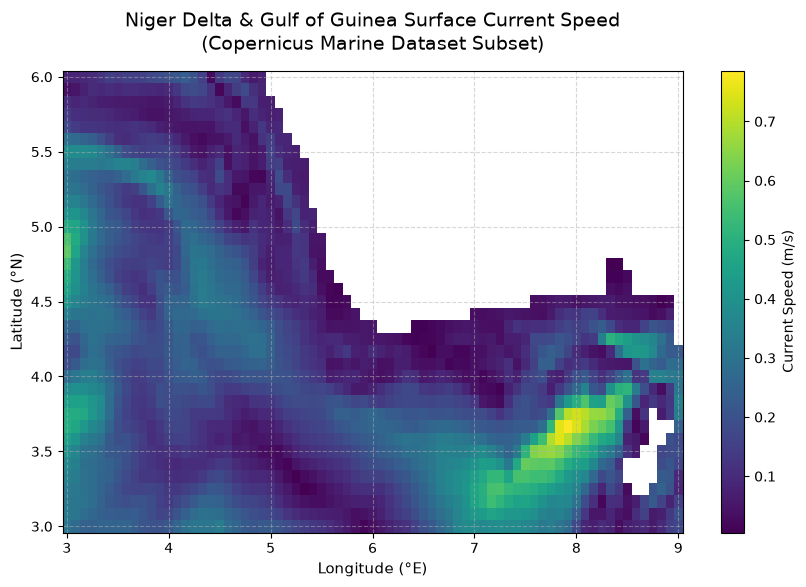

In [3]:
import os
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

# 1. Load the downloaded Copernicus NetCDF file
file_path = "./data/niger_delta_currents.nc"
print(f"Loading grid data from: {file_path}")
ds = xr.open_dataset(file_path)

# 2. Extract individual velocity vector components
# uo = Eastward water velocity (u) | vo = Northward water velocity (v)
u = ds['uo']
v = ds['vo']

# 3. Calculate Current Speed using the vector magnitude formula: sqrt(u^2 + v^2)
current_speed = np.sqrt(u**2 + v**2)

# Assign readable metadata names and attributes for your thesis charts
current_speed.name = "current_speed"
current_speed.attrs['units'] = 'm/s'
current_speed.attrs['long_name'] = 'Sea Surface Current Speed'

print("Formula successfully applied to the data grid structure.")

# 4. Generate a visual spatial plot of the surface current
plt.figure(figsize=(10, 6))

# Slicing the very first hourly time step [0] and depth layer [0] to create the map
map_slice = current_speed.isel(time=0, depth=0)
map_slice.plot(cmap='viridis', cbar_kwargs={'label': 'Current Speed (m/s)'})

# Refine chart presentation
plt.title('Niger Delta & Gulf of Guinea Surface Current Speed\n(Copernicus Marine Dataset Subset)', fontsize=14, pad=15)
plt.xlabel('Longitude (°E)', fontsize=11)
plt.ylabel('Latitude (°N)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)

# Render map directly in your notebook browser
plt.show()
